# Manual Day — Statistical Mechanics & the Ising Model

Closed-agent, ~60 min. Complete every `# FILL IN` cell, then run the check.

**Five problems. Work in order, as many as time permits.** The last two are challenges.

Problems 1 to 3 are the part you submit. Together they rebuild last year's Ising code in
three pieces: the setup of the lattice, the Metropolis sampling, and the physics of the
phase transition. Each piece ends with a check you can run.

## Mini-lecture: statistical mechanics and the Ising model

### The canonical ensemble

Most physical systems aren't isolated. They exchange energy with an environment so
much larger than themselves that it acts as a heat bath at a fixed temperature $T$. Put
a small system in contact with the bath and it exchanges energy until it reaches
thermal equilibrium at the bath's temperature.

Imagine many mental copies of the system and the bath. The probability $P_s$ of finding
the system in a microstate $s$ with energy $E_s$ is

$$P_s = \frac{1}{Z}\,e^{-E_s/k_BT}, \qquad Z = \sum_s e^{-E_s/k_BT} .$$

This is the **canonical ensemble**, and the normalization $Z$ is the **partition
function**, a sum over every microstate. Ensemble averages follow from $P_s$. The mean
energy, for instance, is

$$\langle E\rangle = \sum_s E_s\,P_s = \frac1Z \sum_s E_s\,e^{-\beta E_s}, \qquad \beta = \frac{1}{k_BT} .$$

### The Metropolis algorithm

We want the mean of an observable $A$,

$$\langle A\rangle = \frac{\sum_s A_s\,e^{-\beta E_s}}{\sum_s e^{-\beta E_s}} ,$$

where $A_s$ and $E_s$ are its value and the energy in configuration $s$. The sum runs
over every configuration, which for $N$ spins means $2^N$ terms, so we sample a subset
instead. Drawing configurations at random is the hit-or-miss method again and just as
inefficient, because almost every random configuration is improbable and contributes
almost nothing. The fix is importance sampling with the Boltzmann probability itself:
if the $m$ configurations are drawn with probability $P_s$, the weights cancel and

$$\langle A\rangle \simeq \frac1m \sum_{s=1}^{m} A_s .$$

To draw them, take a random walk through configuration space. From configuration $i$,
propose a configuration $j$ and hop to it with the **transition probability**

$$W = \min\left(1, \frac{P_j}{P_i}\right) = \min\left(1, e^{-\beta(E_j - E_i)}\right) .$$

Only the ratio $P_j/P_i$ enters, so we never need $Z$. Other rules work too, provided
they satisfy **detailed balance**,

$$W(i\to j)\,e^{-\beta E_i} = W(j\to i)\,e^{-\beta E_j} ,$$

and one common alternative is the heat-bath rule
$W(i\to j) = 1/\big(e^{\beta(E_j - E_i)} + 1\big)$, which accepts a move with
$\Delta E = 0$ half the time.

In the language of statistical mechanics, a Monte Carlo simulation goes like this:

1. Set up an initial configuration.
2. Make a random trial change, for example choose a spin at random and try to flip it.
3. Compute the change in energy $\Delta E$ that the trial change would cause.
4. If $\Delta E \le 0$, accept the new configuration.
5. Otherwise accept it with probability $e^{-\beta\Delta E}$: draw a uniform $r$ in
   $[0, 1]$ and accept if $r \le e^{-\beta\Delta E}$. If you reject it, keep the
   previous configuration.
6. Repeat, and compute averages over configurations that are statistically independent
   of each other.

Detailed balance isn't enough on its own. The algorithm must also be **ergodic**: the
moves must be able to reach every part of configuration space. If local moves can't
reach some region, you need global moves or a smarter update.

### The Ising model

A ferromagnet has a spontaneous magnetization with no applied field, but only below the
Curie temperature $T_c$. Above $T_c$ the magnetization vanishes, so $T_c$ separates a
disordered phase at $T > T_c$ from a ferromagnetic one at $T < T_c$. The Ising model is
very simple, but it already contains much of the physics of that transition.

Put $N$ sites on a lattice, each with a spin $s_i = \pm 1$. The energy of a
configuration is

$$E = -J \sum_{\langle ij\rangle} s_i s_j - h \sum_{i=1}^{N} s_i ,$$

where the first sum runs over nearest-neighbor pairs. For $J > 0$ aligned neighbors
lower the energy, so the low-energy states are ferromagnetic. For $J < 0$ antiparallel
neighbors are favored and the ground state is antiferromagnetic. A field $h$ pointing
up gives each up spin an extra energy $-h$ and each down spin $+h$. Today $J = 1$,
$h = 0$, and $k_B = 1$. Instead of following Newton's laws, the dynamics is a sequence
of spin flips: choose a spin at random and try to flip it.

### What to measure

The magnetization is $M = \sum_i s_i$. With $h = 0$ the system is as likely to have its
spins pointing down as up, so $\langle M\rangle$ averages to zero. On a computer one
measures $|M|$ instead, which is always positive.

The heat capacity can be measured from its definition, $C = \partial\langle E\rangle/\partial T$,
or from the energy fluctuations in the canonical ensemble,

$$C = \frac{\langle E^2\rangle - \langle E\rangle^2}{k_BT^2} .$$

The magnetic susceptibility $\chi = \partial\langle M\rangle/\partial h$ at $h = 0$
measures how readily the spins respond to a field. It's a response function, and it
follows from the magnetization fluctuations,

$$\chi = \frac{\langle M^2\rangle - \langle M\rangle^2}{k_BT} .$$

### Moves, boundaries, and equilibration

To flip the spin at $(x, y)$, compute

$$U = J\,s(x,y)\,\big[s(x+1,y) + s(x-1,y) + s(x,y+1) + s(x,y-1)\big] .$$

The energy change of the flip is $\Delta U = 2U$. Flip if $\Delta U \le 0$, and
otherwise flip only if a uniform random number is below $e^{-\Delta U/k_BT}$. The sum in
brackets only takes the values $-4, -2, 0, 2, 4$, so every possible $\Delta U$ and its
Boltzmann factor can be stored in a **lookup table** once per temperature instead of
recomputed at every step.

We want the properties of an infinite system, so the boundaries matter. With free
boundaries the spins at the ends of a chain have only one neighbor each. **Periodic
boundary conditions** are usually better: the two ends interact, the chain becomes a
ring, and every spin has the same number of neighbors, so the origin can be put
anywhere. In 2D the lattice wraps in both $x$ and $y$ and becomes a torus. The cost is
that no two spins can be farther apart than half the system size.

A random initial configuration works, but equilibration can take a large fraction of
the computer time. The most practical start is an equilibrium configuration from a
previous run at a nearby temperature. Two more tricks: store the neighbors of every
site in a table so you never recompute them, and keep the transition probabilities in
lookup tables.

### What to expect

At low $T$ the lattice is ordered and $|M|/N$ is near one. At high $T$ it's disordered
and $|M|/N$ is near zero. In between, the magnetization falls steeply and both $C$ and
$\chi$ peak. Onsager solved the 2D model exactly, so we know where:

$$k_BT_c = \frac{2J}{\ln\big(1 + \sqrt 2\big)} \approx 2.269\,J .$$

His solution also gives the exact energy per spin at every $T$ and the spontaneous
magnetization below $T_c$, $|M|/N = \big(1 - \sinh^{-4}(2J/k_BT)\big)^{1/8}$. Both are
coded below as references, and a finite lattice should land close to them away from
$T_c$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import ellipk

## Problem 1 — setup: the lattice, its neighbors, and its energy

The first half of last year's `Ising` class builds the lattice. Number the sites
$n = i_x + L\,i_y$ for $i_x, i_y = 0, \dots, L-1$, so there are $N = L^2$ of them. The
**neighbor table** `nn` has one row per site, and `nn[n, Direction.RIGHT]` is the site to
the right of `n`, and likewise for `TOP`, `LEFT`, and `BOTTOM`. Moving right adds 1 and
moving up adds $L$, so write those four neighbors for a site away from the edges. At the
edges, periodic boundaries wrap around: the right neighbor of a site in the last column
is the first site in the same row, and the top neighbor of a site in the top row is the
site in the same column of the bottom row. Last year's four `if` statements that do this
are given. They come after your four lines and overwrite them only for sites on an edge.

Then compute the total magnetization `Mtot` $= \sum_n s_n$ and the total energy

$$E = -J \sum_n s_n\,\big(s_{\mathrm{right}(n)} + s_{\mathrm{top}(n)}\big) .$$

Using only the right and top neighbors counts each bond once. The spins start random,
as last year, or all up with `start="up"`. The check also passes in an explicit
configuration.

**Known answers.** All spins up gives $E = -2JN$ and $M = N$, since every site has two
bonds of its own and each one contributes $-J$. A checkerboard gives $E = +2JN$ and
$M = 0$. The neighbor table must be consistent: the left neighbor of your right neighbor
is you, every site is a neighbor of exactly four others, and site 0, in the corner, has
its left neighbor at $L - 1$ and its bottom neighbor at $L(L-1)$. For any configuration,
your energy has to match an independent calculation done with `np.roll`.

In [2]:
# GIVEN — last year's direction labels and the coupling (do not change)
class Direction:
    RIGHT, TOP, LEFT, BOTTOM = list(range(4))

J = 1.0

In [4]:
# FILL IN: the setup half of last year's Ising class. Fill in the interior neighbors (the
#          wrap at the edges is given), then the total magnetization and the total energy.
class IsingLattice:
    def __init__(self, L, J, rng, start="random"):
        self.L, self.N, self.J, self.rng = L, L*L, J, rng

        # neighbor table with periodic boundary conditions
        self.nn = np.zeros((self.N, 4), dtype=int)
        for iy in range(L):
            for ix in range(L):
                n = ix + L*iy
                # the four neighbors of n away from the edges: left, right, top, bottom
                self.nn[n, Direction.LEFT] = n - 1
                self.nn[n, Direction.RIGHT] = n + 1
                self.nn[n, Direction.TOP] = n + L
                self.nn[n, Direction.BOTTOM] = n - L
                # periodic boundaries (given): sites on an edge wrap to the opposite side
                if ix == 0:
                    self.nn[n, Direction.LEFT] = n + L - 1
                if ix == L - 1:
                    self.nn[n, Direction.RIGHT] = n - (L - 1)
                if iy == 0:
                    self.nn[n, Direction.BOTTOM] = n + (L - 1)*L
                if iy == L - 1:
                    self.nn[n, Direction.TOP] = n - (L - 1)*L

        # starting spins: random as last year, all up, or an explicit configuration
        if isinstance(start, str):
            self.spin = np.ones(self.N, dtype=int) if start == "up" else rng.choice([-1, 1], size=self.N)
        else:
            self.spin = np.array(start, dtype=int)

        self.Mtot = np.sum(self.spin)                # total magnetization
        self.E = -self.J * sum(self.spin[n] * (self.spin[self.nn[n, Direction.RIGHT]] + self.spin[self.nn[n, Direction.TOP]])
                for n in range(self.N))                   # total energy, each bond counted once

In [5]:
# CHECK — do not edit
def reference_energy(spin, L):
    s = spin.reshape(L, L)                         # row iy, column ix
    return -J * np.sum(s * np.roll(s, -1, axis=1) + s * np.roll(s, -1, axis=0))

rng = np.random.default_rng(0)
L = 6
lat = IsingLattice(L, J, rng)
nn = lat.nn
grid = np.arange(L*L).reshape(L, L)
assert nn.shape == (L*L, 4), "nn should have one row per site and one column per direction"
assert np.all(nn[:, Direction.RIGHT] == np.roll(grid, -1, axis=1).ravel()), "RIGHT neighbors are off"
assert np.all(nn[:, Direction.TOP] == np.roll(grid, -1, axis=0).ravel()), "TOP neighbors are off"
assert all(nn[nn[n, Direction.RIGHT], Direction.LEFT] == n and nn[nn[n, Direction.TOP], Direction.BOTTOM] == n
           for n in range(L*L)), "the left neighbor of your right neighbor should be you"
assert np.all(np.bincount(nn.ravel(), minlength=L*L) == 4), "every site should be a neighbor of exactly four others"
print("site 0 neighbors: right %d, top %d, left %d, bottom %d" % tuple(nn[0]))
assert nn[0, Direction.LEFT] == L - 1 and nn[0, Direction.BOTTOM] == L*(L - 1)

up = IsingLattice(L, J, rng, start="up")
checker = IsingLattice(L, J, rng, start=[(-1)**(ix + iy) for iy in range(L) for ix in range(L)])
print("all up:       E = %+.0f  (expect %+.0f)   M = %d" % (up.E, -2*J*L*L, up.Mtot))
print("checkerboard: E = %+.0f  (expect %+.0f)   M = %d" % (checker.E, 2*J*L*L, checker.Mtot))
assert up.E == -2*J*L*L and up.Mtot == L*L
assert checker.E == 2*J*L*L and checker.Mtot == 0
for seed in range(5):
    r = IsingLattice(L, J, np.random.default_rng(seed))
    assert r.E == reference_energy(r.spin, L) and r.Mtot == r.spin.sum(), "energy or magnetization of a random start is off"
print("random starts: energy and magnetization match the np.roll reference")
print("OK")

site 0 neighbors: right 1, top 6, left 5, bottom 30
all up:       E = -72  (expect -72)   M = 36
checkerboard: E = +72  (expect +72)   M = 0
random starts: energy and magnetization match the np.roll reference
OK


## Problem 2 — sampling: the Metropolis move

The second half of last year's class adds a temperature and the Metropolis move. The
energy change of flipping spin $s_i$ is

$$\Delta E = 2J\,s_i \sum_{j \in \text{nbr}(i)} s_j ,$$

and the neighbor sum `spin_sum` is one of $-4, -2, 0, 2, 4$. So `set_temp` (given)
fills two lookup tables once per temperature, indexed by `[s_i + 1, spin_sum + 4]`:
`de` holds $\Delta E$, and `w` holds $\min\big(1, e^{-\Delta E/T}\big)$.

Write `metropolis()`, one attempted flip. Pick a random site `i` with `self.rng.integers(self.N)`, add up
its four neighbors, and look up `deltaE`. Accept the flip if `deltaE <= 0`, or otherwise
if a uniform random number `self.rng.random()` is below the matching entry of `w`. When you accept, flip the
spin and update `Mtot` and `E` by the change, so you never recompute them from scratch.
Return 1 if you accepted and 0 if not. The given `sweep()` makes $N$ attempts, one per
spin on average. Warm-up and measurement below are counted in sweeps.

**Known answers.** After any number of moves, the `E` and `Mtot` you've been updating
must agree exactly with a fresh calculation from the spins. On a $4 \times 4$ lattice
there are only $2^{16} = 65{,}536$ configurations, so the check computes
$\langle E\rangle/N$ and $\langle |M|\rangle/N$ exactly by summing over all of them.
At $T = 2.5$ that gives $-1.3791$ and $0.7647$, and your sampler should match within its
error bars. Last year's run at $L = 10$ and $T = 3$ should give an energy per spin close
to Onsager's $-0.817$.

In [6]:
# GIVEN — exact answers to check against (do not change)
TC = 2 / np.log(1 + np.sqrt(2))                    # Onsager's critical temperature, 2.269

def onsager_energy(T):
    # exact energy per spin of the infinite 2D Ising model with J = 1
    K = 1 / np.asarray(T, dtype=float)
    k = 2 * np.sinh(2*K) / np.cosh(2*K)**2
    return -1 / np.tanh(2*K) * (1 + 2/np.pi * (2*np.tanh(2*K)**2 - 1) * ellipk(k**2))

def onsager_magnetization(T):
    # exact spontaneous magnetization per spin; zero above TC
    K = 1 / np.asarray(T, dtype=float)
    x = 1 - np.sinh(2*K)**-4
    return np.where(x > 0, np.abs(x)**0.125, 0.0)

def exact_4x4(T):
    # <E>/N and <|M|>/N for the 4 x 4 periodic lattice, summing all 2**16 configurations
    idx = np.arange(2**16)
    s = (((idx[:, None] >> np.arange(16)) & 1) * 2 - 1).reshape(-1, 4, 4)
    E = -(s * np.roll(s, -1, 2) + s * np.roll(s, -1, 1)).sum((1, 2))
    M = np.abs(s.sum((1, 2)))
    w = np.exp(-(E - E.min()) / T)
    return (w * E).sum() / w.sum() / 16, (w * M).sum() / w.sum() / 16

In [11]:
# FILL IN: the sampling half of last year's class. set_temp builds the lookup tables;
#          you write metropolis(), one attempted single-spin flip.
class Ising(IsingLattice):
    def __init__(self, L, J, T, rng, start="random"):
        super().__init__(L, J, rng, start)
        self.TWOJ = 2. * J
        self.de = np.zeros((3, 9))     # energy change of a flip, indexed by [s_i + 1, spin_sum + 4]
        self.w = np.zeros((3, 9))      # its Boltzmann factor min(1, exp(-de/T)), same indexing
        self.set_temp(T)

    def set_temp(self, T):
        self.T = T
        self.beta = 1. / T
        for spin_sum in range(-4, 5):
            self.de[0, spin_sum + 4] = -self.TWOJ * spin_sum      # flipping s_i = -1
            self.de[2, spin_sum + 4] = self.TWOJ * spin_sum       # flipping s_i = +1
            p = np.exp(-self.beta * self.de[0, spin_sum + 4])
            self.w[0, spin_sum + 4] = min(p, 1.)
            self.w[2, spin_sum + 4] = min(1. / p, 1.)

    def metropolis(self):
        # one attempted flip at a random site; return 1 if accepted, 0 if not
        i = self.rng.integers(self.N)
        s_i = self.spin[i]
        spin_sum = sum(self.spin[j] for j in self.nn[i])
        deltaE = self.de[s_i + 1, spin_sum + 4]
        if deltaE <= 0 or self.rng.random() < self.w[s_i + 1, spin_sum + 4]:
            self.spin[i] = -s_i
            self.Mtot -= 2 * s_i
            self.E += deltaE
            return 1

        return 0

    def sweep(self):
        # N attempted flips, one per spin on average; return the number accepted
        return sum(self.metropolis() for _ in range(self.N))

bookkeeping: E and Mtot match the spins after 200 sweeps; acceptance 0.30
4 x 4, T = 2.0:  <E>/N = -1.7524 +/- 0.0055 (exact -1.7554)   <|M|>/N = 0.9172 +/- 0.0023 (exact 0.9189)
4 x 4, T = 2.5:  <E>/N = -1.3892 +/- 0.0080 (exact -1.3791)   <|M|>/N = 0.7689 +/- 0.0035 (exact 0.7647)

L = 10, T = 3:  <E>/N = -0.8274 (Onsager -0.8173)   <|M|>/N = 0.279   acceptance 0.46
OK


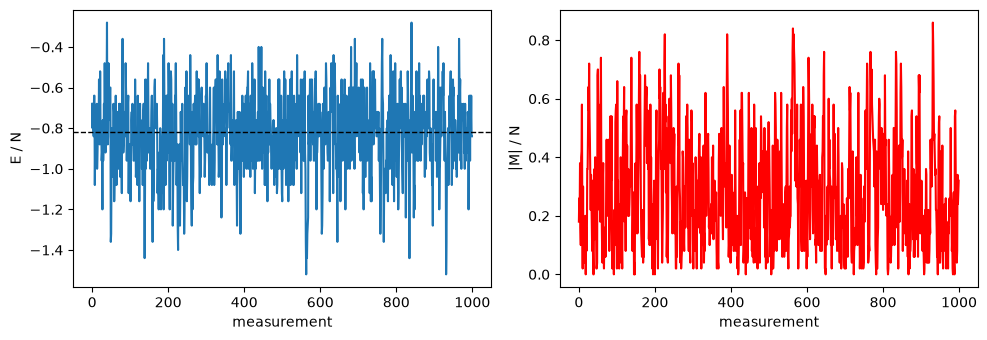

In [12]:
# CHECK — do not edit
rng = np.random.default_rng(1)

# 1. bookkeeping: the E and Mtot you update must match a fresh calculation
S = Ising(8, J, 2.5, rng)
accepted = sum(S.sweep() for _ in range(200))
assert S.E == reference_energy(S.spin, 8) and S.Mtot == S.spin.sum(), "E or Mtot drifted from the spins"
print("bookkeeping: E and Mtot match the spins after 200 sweeps; acceptance %.2f" % (accepted / (200 * S.N)))

# 2. the 4 x 4 lattice against exact enumeration of all 65,536 configurations
for T in (2.0, 2.5):
    S = Ising(4, J, T, rng, start="up")
    for _ in range(500):
        S.sweep()
    e, m = np.zeros(20000), np.zeros(20000)
    for k in range(20000):
        S.sweep()
        e[k], m[k] = S.E / 16, abs(S.Mtot) / 16
    err_e = e.reshape(20, -1).mean(1).std(ddof=1) / np.sqrt(20)   # error bars from 20 blocks of 1000 sweeps
    err_m = m.reshape(20, -1).mean(1).std(ddof=1) / np.sqrt(20)
    ex_e, ex_m = exact_4x4(T)
    print("4 x 4, T = %.1f:  <E>/N = %.4f +/- %.4f (exact %.4f)   <|M|>/N = %.4f +/- %.4f (exact %.4f)"
          % (T, e.mean(), err_e, ex_e, m.mean(), err_m, ex_m))
    assert abs(e.mean() - ex_e) < 5 * err_e and abs(m.mean() - ex_m) < 5 * err_m, "the sampler disagrees with exact enumeration"

# 3. last year's run: L = 10, T = 3
L, Temp, Nwarmup, Nsteps, Ndecorr = 10, 3.0, 100, 1000, 3
S = Ising(L, J, Temp, rng)
for _ in range(Nwarmup):
    S.sweep()
E, M = np.zeros(Nsteps), np.zeros(Nsteps)
naccept = 0
for k in range(Nsteps):
    for _ in range(Ndecorr):
        naccept += S.sweep()
    E[k], M[k] = S.E / S.N, abs(S.Mtot) / S.N
print("\nL = %d, T = %g:  <E>/N = %.4f (Onsager %.4f)   <|M|>/N = %.3f   acceptance %.2f"
      % (L, Temp, E.mean(), onsager_energy(Temp), M.mean(), naccept / (Nsteps * Ndecorr * S.N)))
assert abs(E.mean() - onsager_energy(Temp)) < 0.04, "the energy at T = 3 is far from Onsager's"
print("OK")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.5))
a1.plot(E); a1.axhline(onsager_energy(Temp), ls="--", c="k", lw=1); a1.set_xlabel("measurement"); a1.set_ylabel("E / N")
a2.plot(M, c="r"); a2.set_xlabel("measurement"); a2.set_ylabel("|M| / N")
plt.tight_layout();

## Problem 3 — physics: the phase transition

This is last year's temperature sweep. Start ordered at the lowest temperature and carry
the same lattice upward, calling `set_temp` at each new $T$, so each run starts from an
equilibrium configuration at a nearby temperature. At each temperature, warm up for
`n_warm` sweeps, then take `n_steps` measurements separated by `n_decorr` sweeps,
accumulating $E$, $|M|$, $E^2$, and $M^2$. From their averages, compute per spin

$$c = \frac{\langle E^2\rangle - \langle E\rangle^2}{N\,T^2}, \qquad
\chi = \frac{\langle M^2\rangle - \langle |M|\rangle^2}{N\,T},$$

and last year's error bars on $\langle E\rangle/N$ and $\langle |M|\rangle/N$,
$\sqrt{(\langle E^2\rangle - \langle E\rangle^2)/n_{\rm steps}}\,/N$ and
$\sqrt{(\langle M^2\rangle - \langle |M|\rangle^2)/n_{\rm steps}}\,/N$. Use the array `temps` in these
formulas, so each temperature gets its own $T$. The $\langle |M|\rangle$ in $\chi$ stands in
for the lecture's $\langle M\rangle$, which averages to zero at $h = 0$. The temperatures run from 0.2 to 7.8 in steps of 0.2, as last year, on the same
$10 \times 10$ lattice.

**Known answers.** At low temperature the energy and magnetization land on Onsager's:
at $T = 1.6$ the energy per spin is $-1.9282$ and $|M|/N = 0.9796$. At high temperature
the lattice is disordered. At $T = 3.6$ the energy per spin is $-0.6363$ and $|M|/N$ is
small, nonzero only because the lattice is finite, and the heat capacity per spin is close
to Onsager's $0.2285$. Between them $|M|$ drops steeply, and
both $c$ and $\chi$ peak near $T_c = 2.269$. On a lattice this small the peaks are
broad, and on last year's grid of temperatures they land anywhere from 2.2 to 2.6.

In [13]:
# GIVEN — last year's sweep (do not change)
L = 10
N = L * L
temps = np.arange(0.2, 8, 0.2)
n_warm, n_steps, n_decorr = 200, 1000, 1
rng = np.random.default_rng(2)

In [14]:
# FILL IN: last year's temperature sweep. Carry one lattice upward in T with set_temp,
#          warm up, measure, and turn the averages into c, chi, and error bars.
S = Ising(L, J, temps[0], rng, start="up")
Et, Mt, E2t, M2t = np.zeros(temps.size), np.zeros(temps.size), np.zeros(temps.size), np.zeros(temps.size)
for n, T in enumerate(temps):
    S.set_temp(T)
    # n_warm sweeps to equilibrate at the new temperature
    for _ in range(n_warm):
        S.sweep()
    for _ in range(n_steps):
        # n_decorr sweeps, then add S.E, abs(S.Mtot), S.E**2, S.Mtot**2 to Et[n], Mt[n], E2t[n], M2t[n]
        for _ in range(n_decorr):
            S.sweep()

        Et[n] += S.E
        Mt[n] += abs(S.Mtot)
        E2t[n] += S.E**2
        M2t[n] += S.Mtot**2

Et, Mt, E2t, M2t = Et / n_steps, Mt / n_steps, E2t / n_steps, M2t / n_steps
e, m = Et / N, Mt / N
c = (E2t - Et**2) / (N * temps**2)                       # heat capacity per spin, from the energy fluctuations
chi = (M2t - Mt**2) / (N * temps)                     # susceptibility per spin, from the magnetization fluctuations
ErrorE = np.sqrt((E2t - Et**2) / n_steps) / N                  # last year's error bars on e and m
ErrorM = np.sqrt((M2t - Mt**2) / n_steps) / N

T = 1.6:  E/N = -1.9254 (Onsager -1.9282)   |M|/N = 0.9786 (Onsager 0.9796)
T = 3.6:  E/N = -0.6344 (Onsager -0.6363)   |M|/N = 0.1802 (finite-size remnant)
T = 3.6:  heat capacity per spin = 0.2305 (Onsager 0.2285)

heat capacity peaks at T = 2.2, susceptibility at T = 2.2   (Onsager Tc = 2.269)
OK


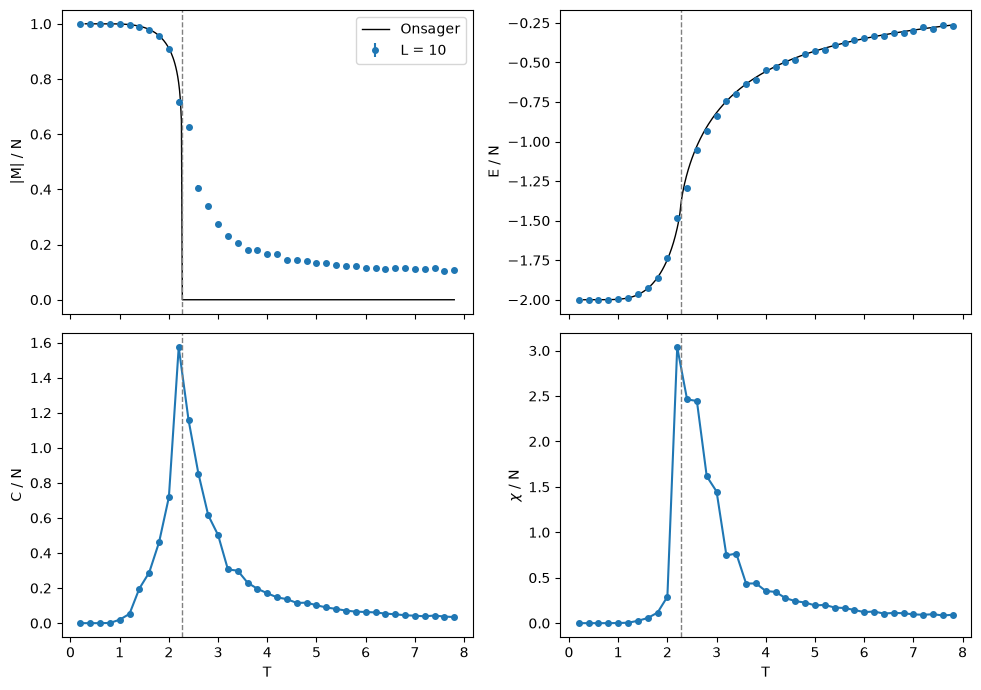

In [15]:
# CHECK — do not edit
lo, hi = np.argmin(abs(temps - 1.6)), np.argmin(abs(temps - 3.6))
print("T = %.1f:  E/N = %.4f (Onsager %.4f)   |M|/N = %.4f (Onsager %.4f)"
      % (temps[lo], e[lo], onsager_energy(temps[lo]), m[lo], onsager_magnetization(temps[lo])))
print("T = %.1f:  E/N = %.4f (Onsager %.4f)   |M|/N = %.4f (finite-size remnant)"
      % (temps[hi], e[hi], onsager_energy(temps[hi]), m[hi]))
assert abs(e[lo] - onsager_energy(temps[lo])) < 0.01 and abs(m[lo] - onsager_magnetization(temps[lo])) < 0.01, \
    "the ordered phase disagrees with Onsager"
assert abs(e[hi] - onsager_energy(temps[hi])) < 0.04 and m[hi] < 0.35, "the disordered phase disagrees with Onsager"
assert np.allclose(c, (E2t - Et**2) / (N * temps**2)) and np.allclose(chi, (M2t - Mt**2) / (N * temps)), \
    "c and chi should follow the formulas above, with each temperature's own T"
assert np.allclose(ErrorE, np.sqrt((E2t - Et**2) / n_steps) / N) and np.allclose(ErrorM, np.sqrt((M2t - Mt**2) / n_steps) / N), \
    "the error bars should follow last year's formula"
C_exact = (onsager_energy(temps[hi] + 1e-4) - onsager_energy(temps[hi] - 1e-4)) / 2e-4
print("T = %.1f:  heat capacity per spin = %.4f (Onsager %.4f)" % (temps[hi], c[hi], C_exact))
assert abs(c[hi] / C_exact - 1) < 0.25, "the heat capacity at high temperature is off from Onsager's"

Tc_heat, Tc_chi = temps[np.argmax(c)], temps[np.argmax(chi)]
print("\nheat capacity peaks at T = %.1f, susceptibility at T = %.1f   (Onsager Tc = %.3f)" % (Tc_heat, Tc_chi, TC))
assert 2.0 <= Tc_heat <= 2.8 and 2.0 <= Tc_chi <= 2.8, "the peaks should sit near Tc"
print("OK")

TT = np.linspace(0.3, 7.8, 400)
TT = TT[abs(TT - TC) > 1e-3]
fig, ax = plt.subplots(2, 2, figsize=(10, 7), sharex=True)
ax[0, 0].errorbar(temps, m, yerr=ErrorM, fmt="o", ms=4, label="L = %d" % L)
ax[0, 0].plot(TT, onsager_magnetization(TT), "k-", lw=1, label="Onsager")
ax[0, 0].set_ylabel("|M| / N"); ax[0, 0].legend()
ax[0, 1].errorbar(temps, e, yerr=ErrorE, fmt="o", ms=4)
ax[0, 1].plot(TT, onsager_energy(TT), "k-", lw=1); ax[0, 1].set_ylabel("E / N")
ax[1, 0].plot(temps, c, "o-", ms=4); ax[1, 0].set_ylabel("C / N"); ax[1, 0].set_xlabel("T")
ax[1, 1].plot(temps, chi, "o-", ms=4); ax[1, 1].set_ylabel(r"$\chi$ / N"); ax[1, 1].set_xlabel("T")
for a in ax.ravel():
    a.axvline(TC, ls="--", c="gray", lw=1)
plt.tight_layout();

## Problem 4 — Challenge: equilibration of the 2D Ising model

This is last year's Exercise 11.2. Write `equilibrate(L, T, n_sweeps, rng)`, which starts
an `Ising` lattice with all spins up and returns the energy and magnetization per spin
after every sweep, the overall acceptance ratio, and the final configuration as an
`L x L` array, in that order: `e, m, acc, spins`, with `m` the signed $M/N$. The check
uses it to work through last year's questions.

1. Run with $L = 8$ and $T = 2$, starting with all spins up. Plot the energy and the
   magnetization against time. How long does the system take to reach equilibrium?
2. Look at the final configuration. Is the system ordered or disordered?
3. Run again at $T = 1.5$ from the same all-up start. How long does it take now?
4. Look at that configuration. Is it more or less ordered than at $T = 2$?
5. Is the acceptance ratio an increasing or decreasing function of $T$? Does Metropolis
   get more or less efficient at low temperature?

**Known answers.** Both runs settle within a few dozen sweeps, because all up is already
close to equilibrium below $T_c$. Once settled, the energy per spin sits near Onsager's
$-1.7456$ at $T = 2$ and $-1.9511$ at $T = 1.5$. Both configurations are ordered, since
both temperatures are below $T_c$, and $T = 1.5$ is the more ordered of the two. The
acceptance ratio rises steadily with $T$. At low temperature almost every proposed flip
is rejected, so most of the computer time goes into moves that are thrown away.

In [ ]:
# FILL IN: one run from all spins up. Return e(t) and m(t) per spin after each sweep,
#          the overall acceptance ratio, and the final spins as an L x L array.
def equilibrate(L, T, n_sweeps, rng):

In [ ]:
# CHECK — do not edit
rng = np.random.default_rng(3)
runs = {T: equilibrate(8, T, 2000, rng) for T in (2.0, 1.5)}
for T, (e_t, m_t, acc, spins) in runs.items():
    print("T = %.1f:  E/N after 500 sweeps = %.4f (Onsager %.4f)   |M|/N = %.3f   acceptance %.3f"
          % (T, e_t[500:].mean(), onsager_energy(T), abs(m_t[500:]).mean(), acc))
assert abs(runs[2.0][0][500:].mean() - onsager_energy(2.0)) < 0.05, "T = 2 should settle near Onsager's energy"
assert abs(runs[1.5][0][500:].mean() - onsager_energy(1.5)) < 0.02, "T = 1.5 should settle near Onsager's energy"
assert abs(runs[1.5][1][500:]).mean() > abs(runs[2.0][1][500:]).mean(), "T = 1.5 should be more ordered than T = 2"

Ts = [1.0, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0]
acc = [equilibrate(8, T, 300, rng)[2] for T in Ts]
print("\nacceptance ratio vs T:", ", ".join("%.1f: %.3f" % (T, a) for T, a in zip(Ts, acc)))
assert np.all(np.diff(acc) > 0), "the acceptance ratio should rise with T"
print("OK")

fig, ax = plt.subplots(1, 4, figsize=(14, 3.2))
for T, (e_t, m_t, _, _) in runs.items():
    ax[0].plot(e_t[:200], label="T = %g" % T); ax[1].plot(m_t[:200], label="T = %g" % T)
ax[0].set_xlabel("sweep"); ax[0].set_ylabel("E / N"); ax[0].legend()
ax[1].set_xlabel("sweep"); ax[1].set_ylabel("M / N")
for a, T in zip(ax[2:], (2.0, 1.5)):
    a.imshow(runs[T][3], cmap="binary", vmin=-1, vmax=1); a.set_title("final spins, T = %g" % T)
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout();

## Problem 5 — Challenge: the correlation function

This is last year's Challenge 11.2: compute the correlation function

$$C(r) = \langle s_0\,s_r\rangle - \langle s_0\rangle\langle s_r\rangle$$

along the $x$ direction, and see how it behaves across the phase transition. With
periodic boundaries every site is equivalent, so average $s_0 s_r$ over all sites as
well as over measurements, and use $\langle s_0\rangle = \langle s_r\rangle = \langle M\rangle/N$ with the
signed magnetization, not the $|M|$ of Problems 2 to 4. Above $T_c$ the signed
$\langle M\rangle$ goes to zero, so there $C(r) = G(r)$.

Write `correlation(S)`, which returns $G(r) = \langle s(x, y)\,s(x + r, y)\rangle$
averaged over the sites of the current configuration for $r = 0, 1, \dots, L/2$, which is
$L/2 + 1$ values. Then write
`measure_correlation(L, T, n_warm, n_steps, rng)`, which starts all up, warms up for `n_warm` sweeps, takes `n_steps` measurements one
sweep apart, and
returns the averaged $G(r)$, the connected $C(r) = G(r) - \langle M/N\rangle^2$, and
$\langle E\rangle/N$. The check runs it on a $24 \times 24$ lattice at $T = 1.8$, at
$T_c$, and at $T = 3$.

**Known answers.** $G(0) = 1$, since $s^2 = 1$. The nearest-neighbor value is fixed by the
energy: $E/N = -J\,\big(G_x(1) + G_y(1)\big)$, so $G(1) = -\langle E\rangle/2N$, which
Onsager gives as $0.9297$ at $T = 1.8$, $1/\sqrt 2 = 0.7071$ at $T_c$, and $0.4087$ at
$T = 3$. Below $T_c$ the spins stay correlated at any distance, and $G(r)$ levels off at
$m^2$, the square of Onsager's spontaneous magnetization, $0.9156$ at $T = 1.8$. The
connected $C(r)$ falls to zero. Above $T_c$, $G(r)$ dies off exponentially within a few
lattice spacings. At $T_c$ it decays slowly, as a power law $r^{-1/4}$, which is the
long-range correlation behind the peaks in Problem 3.

In [ ]:
# FILL IN: G(r) for one configuration, then a run that averages it and returns
#          G(r), the connected C(r), and <E>/N.
def correlation(S):
    # G(r) = <s(x, y) s(x + r, y)> over all sites, for r = 0 .. L/2
    ...

def measure_correlation(L, T, n_warm, n_steps, rng):
    ...

In [ ]:
# CHECK — do not edit
rng = np.random.default_rng(4)
L = 24
results = {T: measure_correlation(L, T, 1500, 2500, rng) for T in (1.8, TC, 3.0)}
G18, C18, e18 = results[1.8]
Gc, Cc, ec = results[TC]
G3, C3, e3 = results[3.0]
assert len(G18) == L // 2 + 1, "G(r) should have L/2 + 1 values, for r = 0, 1, ..., L/2"

for name, T, (G, C, e_avg) in [("1.8", 1.8, results[1.8]), ("Tc", TC, results[TC]), ("3.0", 3.0, results[3.0])]:
    exact = 1/np.sqrt(2) if T == TC else -onsager_energy(T) / 2
    print("T = %-3s  G(0) = %.3f   G(1) = %.4f (Onsager %.4f, and -<E>/2N = %.4f)   G(L/2) = %.4f   C(L/2) = %+.4f"
          % (name, G[0], G[1], exact, -e_avg / 2, G[-1], C[-1]))
    assert abs(G[0] - 1) < 1e-12, "G(0) has to be 1"
    assert abs(G[1] + e_avg / 2) < 0.01, "G(1) should equal -<E>/2N"
assert abs(G18[1] + onsager_energy(1.8) / 2) < 0.01 and abs(G3[1] + onsager_energy(3.0) / 2) < 0.01, "G(1) is off from Onsager"
assert abs(G18[-1] - onsager_magnetization(1.8)**2) < 0.015, "below Tc, G(r) should level off at m^2"
assert abs(C18[-1]) < 0.01 and abs(C3[-1]) < 0.01, "the connected correlation should vanish at large r away from Tc"
assert G3[-1] < 0.02 < Gc[-1], "above Tc G(r) dies off; at Tc it decays slowly"
rr = np.arange(2, 9)
slope = np.polyfit(np.log(rr), np.log(Gc[rr]), 1)[0]
print("\nat Tc, G(r) ~ r^%.2f over r = 2..8   (exact exponent -1/4)" % slope)
print("OK")

r = np.arange(L // 2 + 1)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.8))
for T, lab in [(1.8, "T = 1.8"), (TC, "T = Tc"), (3.0, "T = 3")]:
    a1.plot(r, results[T][0], "o-", ms=4, label=lab)
    a2.semilogy(r[1:], np.abs(results[T][1][1:]) + 1e-6, "o-", ms=4, label=lab)
a1.axhline(onsager_magnetization(1.8)**2, ls="--", c="gray", lw=1)
a1.set_xlabel("r"); a1.set_ylabel("G(r)"); a1.legend()
a2.set_xlabel("r"); a2.set_ylabel("|C(r)|"); a2.legend()
plt.tight_layout();